<a href="https://colab.research.google.com/github/deva1320/MLA0202---ML/blob/main/Exp_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRAINING DATASET
 Outlook Temperature Humidity   Wind PlayTennis
   Sunny         Hot     High   Weak         No
   Sunny         Hot     High Strong         No
Overcast         Hot     High   Weak        Yes
    Rain        Mild     High   Weak        Yes
    Rain        Cool   Normal   Weak        Yes
    Rain        Cool   Normal Strong         No
Overcast        Cool   Normal Strong        Yes
   Sunny        Mild     High   Weak         No
   Sunny        Cool   Normal   Weak        Yes
    Rain        Mild   Normal   Weak        Yes
   Sunny        Mild   Normal Strong        Yes
Overcast        Mild     High Strong        Yes
Overcast         Hot   Normal   Weak        Yes
    Rain        Mild     High Strong         No

INITIAL ENTROPY: 0.9403

INFORMATION GAIN
Outlook : 0.2467
Temperature : 0.0292
Humidity : 0.1518
Wind : 0.0481

GENERATED ID3 DECISION TREE
{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Wind': {'Weak': 'Yes', 

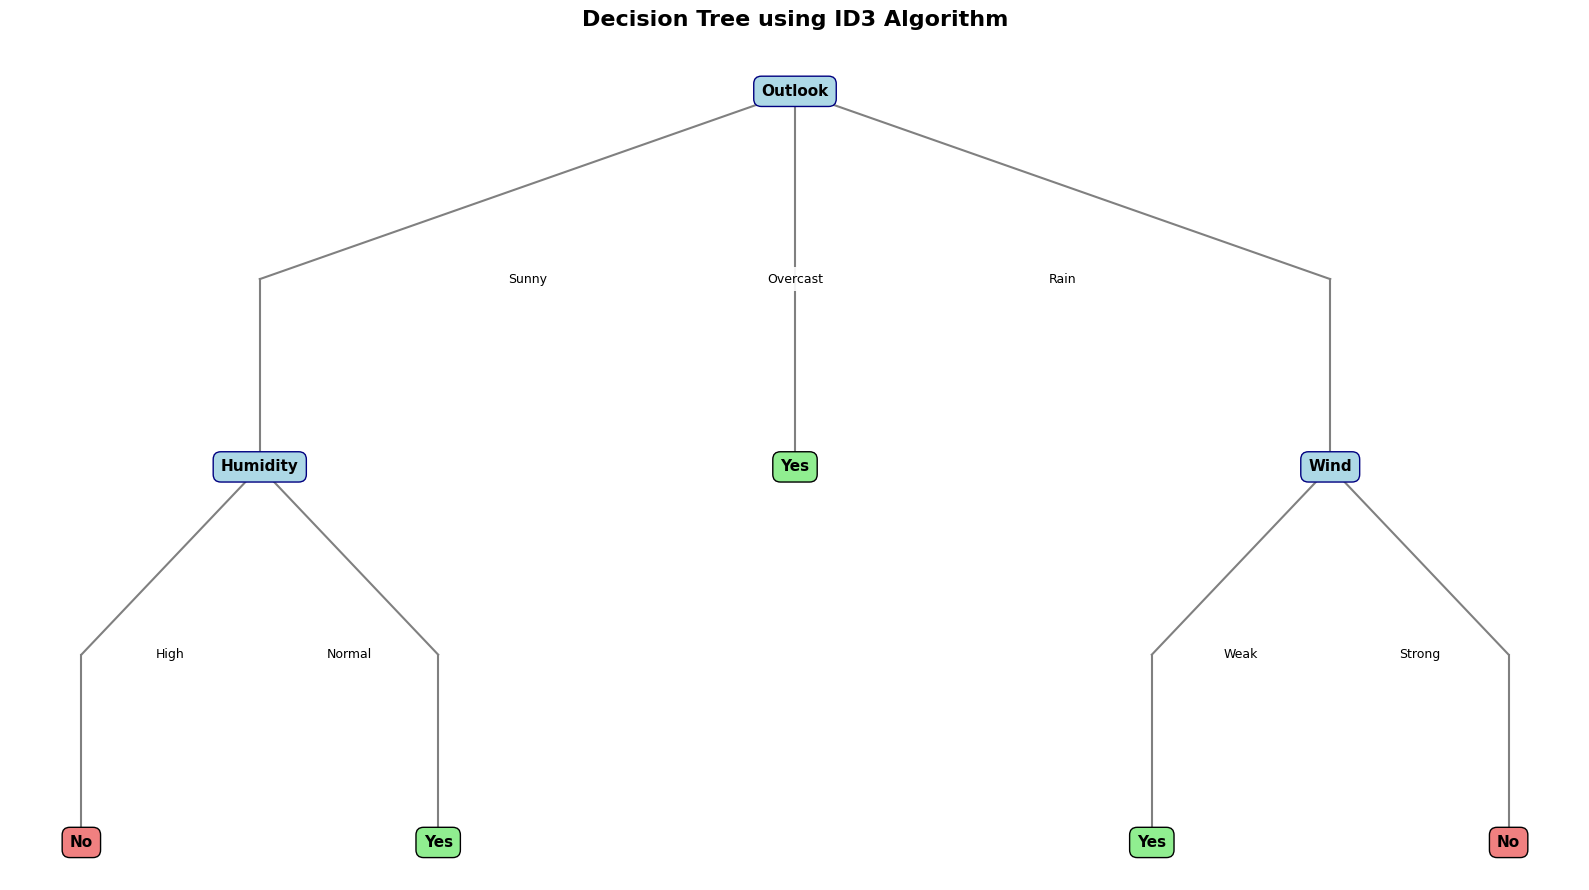


RESULT:
ID3 decision tree constructed successfully.
The new sample was classified as: No


In [1]:

# ============================================================
# MLA02 - FUNDAMENTALS OF MACHINE LEARNING
# EXPERIMENT 3 - ID3 DECISION TREE ALGORITHM
# ============================================================

import math
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Training Dataset: Play Tennis
# ------------------------------------------------------------

data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain", "Rain",
        "Rain", "Overcast", "Sunny", "Sunny", "Rain",
        "Sunny", "Overcast", "Overcast", "Rain"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild", "Cool",
        "Cool", "Cool", "Mild", "Cool", "Mild",
        "Mild", "Mild", "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High", "Normal",
        "Normal", "Normal", "High", "Normal", "Normal",
        "Normal", "High", "Normal", "High"
    ],
    "Wind": [
        "Weak", "Strong", "Weak", "Weak", "Weak",
        "Strong", "Strong", "Weak", "Weak", "Weak",
        "Strong", "Strong", "Weak", "Strong"
    ],
    "PlayTennis": [
        "No", "No", "Yes", "Yes", "Yes",
        "No", "Yes", "No", "Yes", "Yes",
        "Yes", "Yes", "Yes", "No"
    ]
}

df = pd.DataFrame(data)

print("TRAINING DATASET")
print(df.to_string(index=False))

# ------------------------------------------------------------
# 2. Entropy Calculation
# ------------------------------------------------------------

def entropy(target):
    counts = target.value_counts()
    total = len(target)
    result = 0.0

    for count in counts:
        p = count / total
        result -= p * math.log2(p)

    return result

# ------------------------------------------------------------
# 3. Information Gain Calculation
# ------------------------------------------------------------

def information_gain(dataset, attribute, target):
    parent_entropy = entropy(dataset[target])
    weighted_entropy = 0.0

    for value in dataset[attribute].unique():
        subset = dataset[dataset[attribute] == value]

        weighted_entropy += (
            len(subset) / len(dataset)
        ) * entropy(subset[target])

    return parent_entropy - weighted_entropy

# ------------------------------------------------------------
# 4. ID3 Algorithm
# ------------------------------------------------------------

def id3(dataset, attributes, target):

    # If all samples belong to one class
    if dataset[target].nunique() == 1:
        return dataset[target].iloc[0]

    # If no attributes remain, return majority class
    if not attributes:
        return dataset[target].mode()[0]

    # Find the attribute with maximum information gain
    gains = {
        attribute: information_gain(
            dataset, attribute, target
        )
        for attribute in attributes
    }

    best_attribute = max(gains, key=gains.get)

    tree = {best_attribute: {}}

    remaining_attributes = [
        a for a in attributes if a != best_attribute
    ]

    # Create branches for each attribute value
    for value in dataset[best_attribute].unique():

        subset = dataset[
            dataset[best_attribute] == value
        ]

        tree[best_attribute][value] = id3(
            subset,
            remaining_attributes,
            target
        )

    return tree

# ------------------------------------------------------------
# 5. Build the Decision Tree
# ------------------------------------------------------------

target = "PlayTennis"
attributes = [
    "Outlook", "Temperature", "Humidity", "Wind"
]

print("\nINITIAL ENTROPY:",
      round(entropy(df[target]), 4))

print("\nINFORMATION GAIN")

for attribute in attributes:
    print(
        attribute, ":",
        round(information_gain(df, attribute, target), 4)
    )

tree = id3(df, attributes, target)

print("\nGENERATED ID3 DECISION TREE")
print(tree)

# ------------------------------------------------------------
# 6. Classify a New Sample
# ------------------------------------------------------------

def predict(tree, sample):

    if not isinstance(tree, dict):
        return tree

    attribute = next(iter(tree))
    value = sample[attribute]

    if value not in tree[attribute]:
        return "Unknown"

    return predict(tree[attribute][value], sample)

new_sample = {
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "High",
    "Wind": "Strong"
}

prediction = predict(tree, new_sample)

print("\nNEW SAMPLE:")
print(new_sample)

print("PREDICTED CLASS:", prediction)

# ------------------------------------------------------------
# 7. Draw the Decision Tree
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 9))
ax.axis("off")

# Count leaves to position nodes evenly
def count_leaves(node):
    if not isinstance(node, dict):
        return 1

    return sum(
        count_leaves(child)
        for child in node.values()
        for child in child.values()
    )

# Draw tree recursively
def draw_tree(node, x, y, width, level=0,
              parent_x=None, parent_y=None,
              branch_label=""):

    if parent_x is not None:
        mid_y = (parent_y + y) / 2

        ax.plot(
            [parent_x, x],
            [parent_y, mid_y],
            color="gray",
            linewidth=1.5
        )

        ax.plot(
            [x, x],
            [mid_y, y],
            color="gray",
            linewidth=1.5
        )

        ax.text(
            (parent_x + x) / 2,
            mid_y,
            branch_label,
            ha="center",
            va="center",
            fontsize=9,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.9
            )
        )

    if isinstance(node, dict):
        attribute = next(iter(node))

        ax.text(
            x, y, attribute,
            ha="center", va="center",
            fontsize=11, fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor="lightblue",
                edgecolor="navy"
            )
        )

        children = node[attribute]
        total_leaves = sum(
            count_leaves(child)
            for child in children.values()
        )

        current_x = x - width / 2

        for value, child in children.items():

            child_leaves = count_leaves(child)
            child_width = (
                width * child_leaves / total_leaves
            )

            child_x = current_x + child_width / 2
            child_y = y - 1.5

            draw_tree(
                child,
                child_x,
                child_y,
                child_width,
                level + 1,
                x, y,
                str(value)
            )

            current_x += child_width

    else:
        color = (
            "lightgreen" if node == "Yes"
            else "lightcoral"
        )

        ax.text(
            x, y, str(node),
            ha="center", va="center",
            fontsize=11, fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor=color,
                edgecolor="black"
            )
        )

draw_tree(tree, 0.5, 0.92, 0.9)

plt.title(
    "Decision Tree using ID3 Algorithm",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Result
# ------------------------------------------------------------

print("\nRESULT:")
print("ID3 decision tree constructed successfully.")
print("The new sample was classified as:", prediction)
